# NYC Taxi Times

**Author:** Clarice Mottet  

---

## Objective

Build a model to predict the total ride duration for NYC taxis

---

## Dataset
**Source:**
- kaggle


## Table of Contents

- [1. Load Data](#1-load-data)
- [2. Data Cleaning](#2-data-cleaning)
- [3. Exploratory Data Analysis](#3-exploratory-data-analysis)
- [4. Feature Engineering](#4-feature-engineering)
- [5. Modeling](#5-modeling)
- [6. Model Evaluation](#6-model-evaluation)


## Notes

- Random seed = 42
- Train/Test split = pre-determined by datasets given
- Evaluation metric = Root Mean Squared Log Error

# 1. Load Data

In [1]:
#libraries

import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

project_root = Path.cwd().parent          # if notebook is inside notebooks/


## Import in train and test data

In [2]:
#import in the datasets
#quick look over

#establish  file path

raw_path = project_root / "data" / "raw"
os.listdir(raw_path)

df_test = pd.read_csv(raw_path / "test.csv", dtype = str)
df_train = pd.read_csv(raw_path / "train.csv", dtype = str)
df_sample = pd.read_csv(raw_path / "sample_submission.csv", dtype = str)

* Column Check:
train dataset has the columns "dropoff_datetime" and "trip_duration" which test does not

In [3]:
#perform columns check

# print(df_test.columns)
# print(df_train.columns)

list_test_col = list(df_test.columns)
list_train_col = list(df_train.columns)

list_all_col = list_test_col + list_train_col
list_all_col = list(set(list_all_col))
print(list_all_col)

list_test_doesnt = [x for x in list_all_col if x not in list_test_col]
print(list_test_doesnt)

list_train_doesnt = [x for x in list_all_col if x not in list_train_col]
# print(list_train_doesnt)

#so train has the resulting columns for me to be able to compare and train to, theres dropoff_datetime and trip duration



['trip_duration', 'dropoff_longitude', 'pickup_latitude', 'pickup_datetime', 'dropoff_datetime', 'store_and_fwd_flag', 'pickup_longitude', 'vendor_id', 'passenger_count', 'id', 'dropoff_latitude']
['trip_duration', 'dropoff_datetime']


# 2. Data Cleaning

* dtype
* nulls
* duplicates

* Data Type check:

In [4]:
# print(df_train.head())
# print(df_train.columns)

#need to identify dtypes
for col in df_train.columns:
    df_train[col] = df_train[col].str.strip()

#numeric columns
list_col_num = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'trip_duration']
list_col_date = ['pickup_datetime', 'dropoff_datetime']


* convert train and test to numeric

In [5]:
df_ = df_train.copy()

list_convert_num = [x for x in list_col_num if x in df_.columns]
df_[list_convert_num] = df_[list_convert_num].apply(pd.to_numeric)
df_train = df_.copy()

In [6]:
df_t = df_test.copy()

list_convert_num = [x for x in list_col_num if x in df_t.columns]
df_t[list_convert_num] = df_t[list_convert_num].apply(pd.to_numeric)
df_test = df_t.copy()

* convert train and test to datetime

In [7]:
df_ = df_train.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)
df_train = df_.copy()

In [8]:
df_ = df_test.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)


In [9]:
df_.dtypes

id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
dtype: object

* there are no nulls

In [10]:
df_train.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [11]:
df_train.isna().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [12]:
null_counts = df_train.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [13]:
null_counts = df_test.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [14]:
#target variables
var_target = ['dropoff_datetime','trip_duration']

# df_test.columns

* check to make sure trip duration is calculated properly, it is 

In [15]:
df_view = df_train.copy()
df_view['dur_calc'] = (df_view['dropoff_datetime'] - df_view['pickup_datetime']).dt.total_seconds().astype(int)

df_view.head()

df_view['check_dur'] = (df_view['trip_duration'] - df_view['dur_calc']).abs()
df_view_ = df_view[df_view['check_dur']!=0]
# df_view_.head()
df_test.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'],
      dtype='object')

* there are no duplicates by the ID variabe in both train and test

* there are dupliactes by all other fields (1 in test, 7 in train)

In [16]:
#check for duplicates

df_view = df_test.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



In [17]:
df_view = df_train.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



* check for invalid values

In [18]:
df_train.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1458644,1458644,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,2016-04-01 10:10:24.940037120,2016-04-01 10:26:24.432310528,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
min,1.000000e+00,2016-01-01 00:00:17,2016-01-01 00:03:31,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,2016-02-17 16:46:04.249999872,2016-02-17 17:05:32.500000,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,2016-04-01 17:19:40,2016-04-01 17:35:12,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2016-05-15 03:56:08.750000128,2016-05-15 04:10:51.750000128,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,2016-06-30 23:59:39,2016-07-01 23:02:03,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06
std,4.987772e-01,NaN,NaN,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03


# 3. Exploratory Data Analysis

* variable exploration
* distribution

1. Target Variable Analysis
   - histogram
   - log histogram
   - boxplot

   - the trip_duration variable is skewed with 5% outliers, the log_trip_duration is more normally distributed with 1.33% outliers
   - 5897 instances where the pickup and dropoff location are the same
   - add a pickup and dropoff location are the same indicator?

2. Datetime Analysis
   - hour
   - weekday
   - month

   - hour of day has some impact on number of trips (early morning hours have fewer trips)
   - the range of the median by time of day is about 200 seconds and that seems fine, that's a few minutes difference
   - weekday doesn't appear to have an super big change between the trip duration range, does impact some outliers
   - month doesn't appear to have a large impact on trip duration

3. Geographic Analysis
   - pickup map
   - dropoff map
   - distance distributions
   - haversine_distance
   - manhattan_distance

   - there are some outliers to the pickup map and dropoff map
   - over 9% of the data has outliers as calculated by manhattan distance
   - 2.88% outliers as log_manhattan_distance
   - over 9% of the data has outliers by haversine distance
   - 3.1% outliers as log_haversine_distance
   - there are around 251 instances where the trip_duration is around 24 hours regardless of distance of trip
   

4. Numeric Feature Analysis
   - passenger_count

5. Categorical Feature Analysis
   - vendor
   - store_and_fwd_flag

6. Relationships with Target
   - scatterplots
   - boxplots


## Train
* passenger_count - no issues
* pickup_datetime:
    - only jan 2016 - july 2016
    - by date: uniform
    - by time of day: fewer in early morning, some local peaks
    - by day of week: pretty uniform
* passenger_counts:
    - approx 2/3 are 1 passenger only
    - next most as 2 passengers and then 3-6 are about the same frequency
* longitude and latitude:
    - determined how many clusters are needed
    - there are approx 6k instances where the pickup point is the same as the dropoff point
    

In [19]:
df_train.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1458644,1458644,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,2016-04-01 10:10:24.940037120,2016-04-01 10:26:24.432310528,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
min,1.000000e+00,2016-01-01 00:00:17,2016-01-01 00:03:31,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,2016-02-17 16:46:04.249999872,2016-02-17 17:05:32.500000,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,2016-04-01 17:19:40,2016-04-01 17:35:12,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2016-05-15 03:56:08.750000128,2016-05-15 04:10:51.750000128,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,2016-06-30 23:59:39,2016-07-01 23:02:03,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06
std,4.987772e-01,NaN,NaN,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03


### Create new variables here
    - log of trip duration
    - manhattan distance
    - haversine distance

In [48]:
#calculate the log of the trip duration
#calculate the distances to compare to trip duration (particularly the outliers)

df_train["log_trip_duration"] = np.log1p(df_train["trip_duration"])

# Earth's radius in kilometers
R = 6371

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the Haversine distance between two points (in km).
    """
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# Haversine distance
df_train["haversine_distance"] = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

# Manhattan distance (north-south + east-west)
lat_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["pickup_longitude"]
)

lon_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["pickup_latitude"],
    df_train["dropoff_longitude"]
)

df_train["manhattan_distance"] = lat_distance + lon_distance

df_train['log_haversine_distance'] = np.log1p(df_train["haversine_distance"])
df_train['log_manhattan_distance'] = np.log1p(df_train["manhattan_distance"])

In [21]:
df_train[["haversine_distance", "manhattan_distance"]].describe()

,haversine_distance,manhattan_distance
count,1.458644e+06,1.458644e+06
mean,3.440864e+00,4.446860e+00
std,4.296538e+00,5.665930e+00
min,0.000000e+00,0.000000e+00
25%,1.231837e+00,1.570939e+00
50%,2.093717e+00,2.688798e+00
75%,3.875337e+00,4.998990e+00
max,1.240909e+03,1.318480e+03


### Target Variable Analysis
* histogram
* log histogram
* boxplot

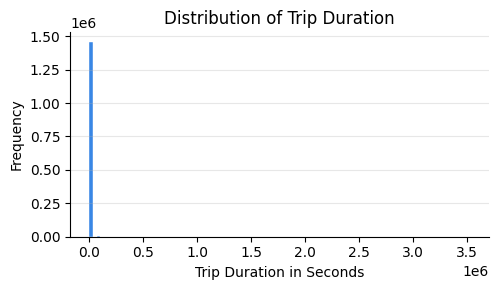

In [22]:
#histogram of trip_duration

fig, ax = plt.subplots(figsize=(5, 3))

ax.hist(df_train['trip_duration'], bins=100, color='#3987e5', edgecolor='white', linewidth=0.3)

ax.set_title('Distribution of Trip Duration')
ax.set_xlabel('Trip Duration in Seconds')
ax.set_ylabel('Frequency')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

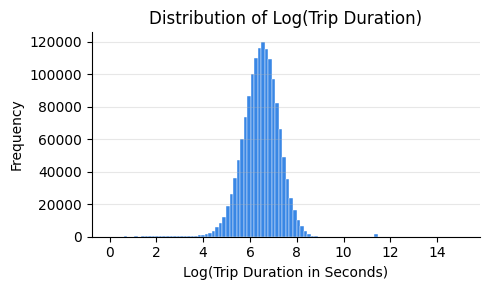

In [23]:
#histogram of log trip duration

fig, ax = plt.subplots(figsize=(5, 3))

log_trip_duration = np.log(df_train['trip_duration'])
ax.hist(log_trip_duration, bins=100, color='#3987e5', edgecolor='white', linewidth=0.3)

ax.set_title('Distribution of Log(Trip Duration)')
ax.set_xlabel('Log(Trip Duration in Seconds)')
ax.set_ylabel('Frequency')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

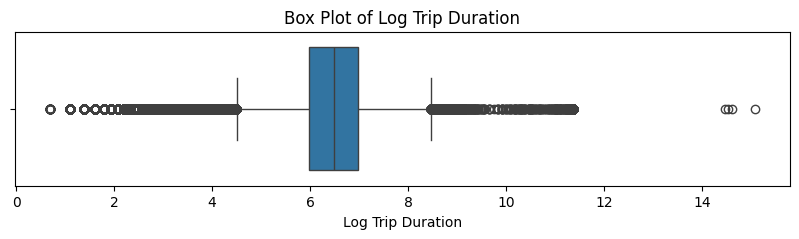

In [24]:
#box plot of log trip duration

plt.figure(figsize=(10, 2))

sns.boxplot(
    x=df_train["log_trip_duration"]
)

plt.xlabel("Log Trip Duration")
plt.title("Box Plot of Log Trip Duration")

plt.show()

In [25]:
# Calculate the quartiles

Q1 = df_train["trip_duration"].quantile(0.25)
Q3 = df_train["trip_duration"].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create a boolean mask for outliers
outliers = (
    (df_train["trip_duration"] < lower_bound) |
    (df_train["trip_duration"] > upper_bound)
)

# Calculate percentage of outliers
outlier_percentage = outliers.mean() * 100

print(f"Outlier percentage: {outlier_percentage:.2f}%")
print(f"Number of outliers: {outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

Outlier percentage: 5.09%
Number of outliers: 74,220
Total observations: 1,458,644


In [26]:
# Calculate the quartiles for the log-transformed variable
Q1 = df_train["log_trip_duration"].quantile(0.25)
Q3 = df_train["log_trip_duration"].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
log_outliers = (
    (df_train["log_trip_duration"] < lower_bound) |
    (df_train["log_trip_duration"] > upper_bound)
)

# Calculate the percentage of outliers
log_outlier_percentage = log_outliers.mean() * 100

print(f"Log-transformed outlier percentage: {log_outlier_percentage:.2f}%")
print(f"Number of outliers: {log_outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

Log-transformed outlier percentage: 1.33%
Number of outliers: 19,449
Total observations: 1,458,644


In [27]:
df_train.nsmallest(10, "trip_duration")[["trip_duration"]]

# df_train.nlargest(10, "trip_duration")[["trip_duration"]]

,trip_duration
35196,1
207497,1
269418,1
279493,1
285635,1
311745,1
346102,1
346959,1
404610,1
451396,1


In [28]:
# df_view = df_train[df_train['trip_duration']<5].copy()
df_view = df_train[(df_train['pickup_latitude']==df_train['dropoff_latitude'])&(df_train['pickup_longitude']==df_train['dropoff_longitude'])].copy()
#there are 33 instances where the trip duration is 1
#check to see if the disance 

df_view['trip_duration'].describe()

count     5897.000000
mean       535.515347
std       1952.094051
min          1.000000
25%         38.000000
50%        350.000000
75%        724.000000
max      86352.000000
Name: trip_duration, dtype: float64

Same pickup/dropoff: 5,897
Percentage: 0.404%


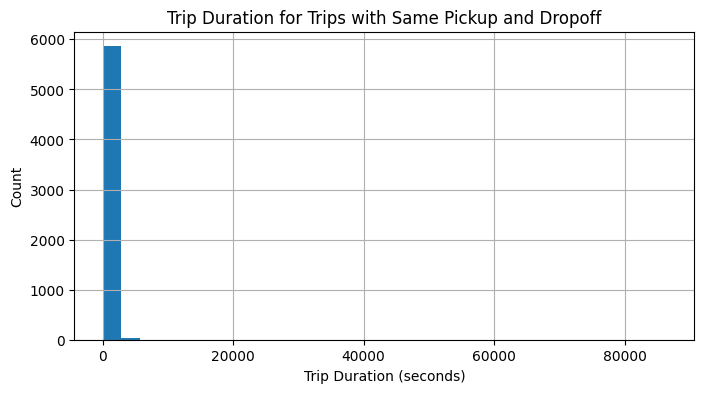

In [29]:
same_location = (
    (df_train["pickup_longitude"] == df_train["dropoff_longitude"]) &
    (df_train["pickup_latitude"] == df_train["dropoff_latitude"])
)

print(f"Same pickup/dropoff: {same_location.sum():,}")
print(f"Percentage: {same_location.mean() * 100:.3f}%")

df_train.loc[
    same_location,
    "trip_duration"
].describe()


plt.figure(figsize=(8,4))

df_train.loc[same_location, "trip_duration"].hist(bins=30)
# df_train.loc[same_location, "log_trip_duration"].hist(bins=30)

plt.xlabel("Trip Duration (seconds)")
plt.ylabel("Count")
plt.title("Trip Duration for Trips with Same Pickup and Dropoff")

plt.show()

In [30]:
df_train.loc[
    same_location,
    "trip_duration"
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

count     5897.000000
mean       535.515347
std       1952.094051
min          1.000000
25%         38.000000
50%        350.000000
75%        724.000000
90%       1197.000000
99%       2609.040000
max      86352.000000
Name: trip_duration, dtype: float64

2. Datetime Analysis
   - hour
   - weekday
   - month

In [31]:
#create hour, weekday and month cyclical variables

def convert_hour(df_, col_):
    df_["hour_"+col_] = df_[col_].dt.hour
    df_["hour_sin_"+col_] = np.sin(2 * np.pi * df_["hour_"+col_] / 24)
    df_["hour_cos_"+col_] = np.cos(2 * np.pi * df_["hour_"+col_] / 24)
    return df_

def convert_day_of_week(df_, col_):
    df_["dow_"+col_] = df_[col_].dt.dayofweek
    df_["dow_sin"+col_] = np.sin(2*np.pi*df_["dow_"+col_]/7)
    df_["dow_cos"+col_] = np.cos(2*np.pi*df_["dow_"+col_]/7)
    return df_

def convert_month(df_, col_):
    df_["month_"+col_] = df_[col_].dt.month
    df_["month_sin"+col_] = np.sin(2*np.pi*df_["month_"+col_]/12)
    df_["month_cos"+col_] = np.cos(2*np.pi*df_["month_"+col_]/12)
    return df_

df_train = convert_hour(df_train, "pickup_datetime")
df_train = convert_day_of_week(df_train, "pickup_datetime")
df_train = convert_month(df_train, "pickup_datetime")



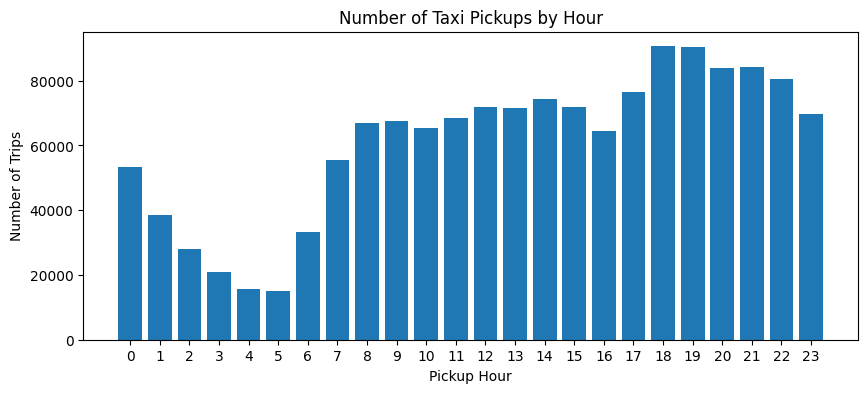

In [32]:
#histogram of time of day

import matplotlib.pyplot as plt

hour_counts = (
    df_train["hour_pickup_datetime"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 4))

plt.bar(hour_counts.index, hour_counts.values)

plt.xticks(range(24))
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")
plt.title("Number of Taxi Pickups by Hour")

plt.show()

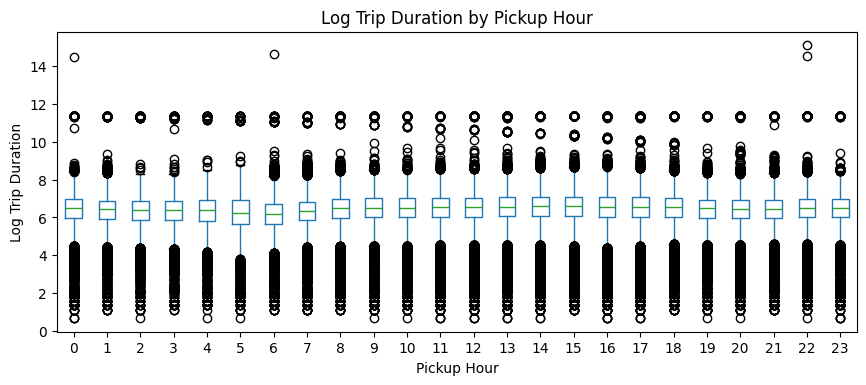

In [33]:
# plot trip duration against time of day

df_train.boxplot(
    column="log_trip_duration",
    by="hour_pickup_datetime",
    figsize=(10, 4),
    grid=False
)

plt.xlabel("Pickup Hour")
plt.ylabel("Log Trip Duration")
plt.title("Log Trip Duration by Pickup Hour")
plt.suptitle("")
plt.show()

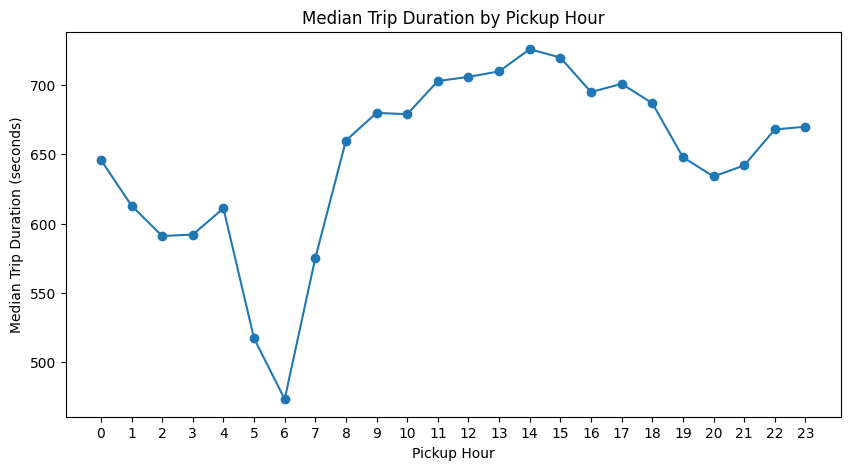

In [34]:
median_duration_by_hour = (
    df_train.groupby("hour_pickup_datetime")["trip_duration"]
    .median()
)

plt.figure(figsize=(10, 5))

plt.plot(
    median_duration_by_hour.index,
    median_duration_by_hour.values,
    marker="o"
)

plt.xticks(range(24))
plt.xlabel("Pickup Hour")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Pickup Hour")

plt.show()

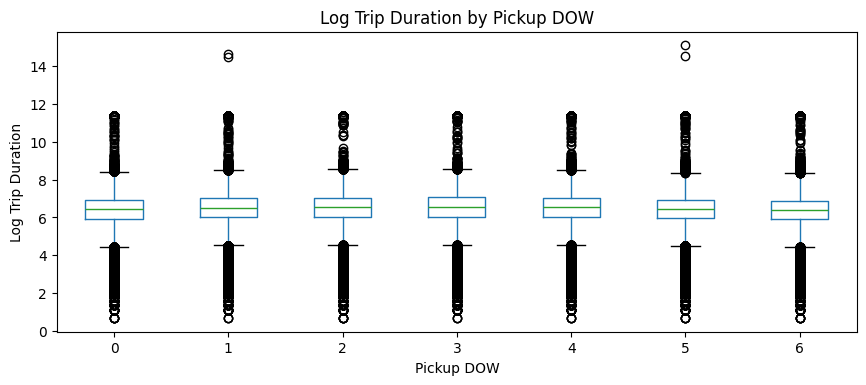

In [35]:
df_train.boxplot(
    column="log_trip_duration",
    by="dow_pickup_datetime",
    figsize=(10, 4),
    grid=False
)

plt.xlabel("Pickup DOW")
plt.ylabel("Log Trip Duration")
plt.title("Log Trip Duration by Pickup DOW")
plt.suptitle("")
plt.show()


3. Geographic Analysis
   - pickup map
   - dropoff map
   - distance distributions

In [36]:
df_train.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,log_trip_duration,...,manhattan_distance,hour_pickup_datetime,hour_sin_pickup_datetime,hour_cos_pickup_datetime,dow_pickup_datetime,dow_sinpickup_datetime,dow_cospickup_datetime,month_pickup_datetime,month_sinpickup_datetime,month_cospickup_datetime
count,1.458644e+06,1458644,1458644,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,...,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,2016-04-01 10:10:24.940037120,2016-04-01 10:26:24.432310528,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02,6.466978e+00,...,4.446860e+00,1.360648e+01,-2.017288e-01,-8.447460e-02,3.050375e+00,-4.690859e-03,-4.016978e-02,3.516818e+00,6.304423e-01,-1.763641e-01
min,1.000000e+00,2016-01-01 00:00:17,2016-01-01 00:03:31,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00,6.931472e-01,...,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,-9.749279e-01,-9.009689e-01,1.000000e+00,1.224647e-16,-1.000000e+00
25%,1.000000e+00,2016-02-17 16:46:04.249999872,2016-02-17 17:05:32.500000,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02,5.986452e+00,...,1.570939e+00,9.000000e+00,-8.660254e-01,-7.071068e-01,1.000000e+00,-7.818315e-01,-9.009689e-01,2.000000e+00,5.000000e-01,-8.660254e-01
50%,2.000000e+00,2016-04-01 17:19:40,2016-04-01 17:35:12,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02,6.496775e+00,...,2.688798e+00,1.400000e+01,-2.588190e-01,-2.588190e-01,3.000000e+00,0.000000e+00,-2.225209e-01,4.000000e+00,8.660254e-01,-5.000000e-01
75%,2.000000e+00,2016-05-15 03:56:08.750000128,2016-05-15 04:10:51.750000128,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03,6.981006e+00,...,4.998990e+00,1.900000e+01,5.000000e-01,7.071068e-01,5.000000e+00,7.818315e-01,6.234898e-01,5.000000e+00,8.660254e-01,5.000000e-01
max,2.000000e+00,2016-06-30 23:59:39,2016-07-01 23:02:03,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06,1.507575e+01,...,1.318480e+03,2.300000e+01,1.000000e+00,1.000000e+00,6.000000e+00,9.749279e-01,1.000000e+00,6.000000e+00,1.000000e+00,8.660254e-01
std,4.987772e-01,NaN,NaN,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03,7.957595e-01,...,5.665930e+00,6.399693e+00,6.728468e-01,7.067159e-01,1.954039e+00,7.104389e-01,7.025963e-01,1.681038e+00,3.347452e-01,6.777789e-01


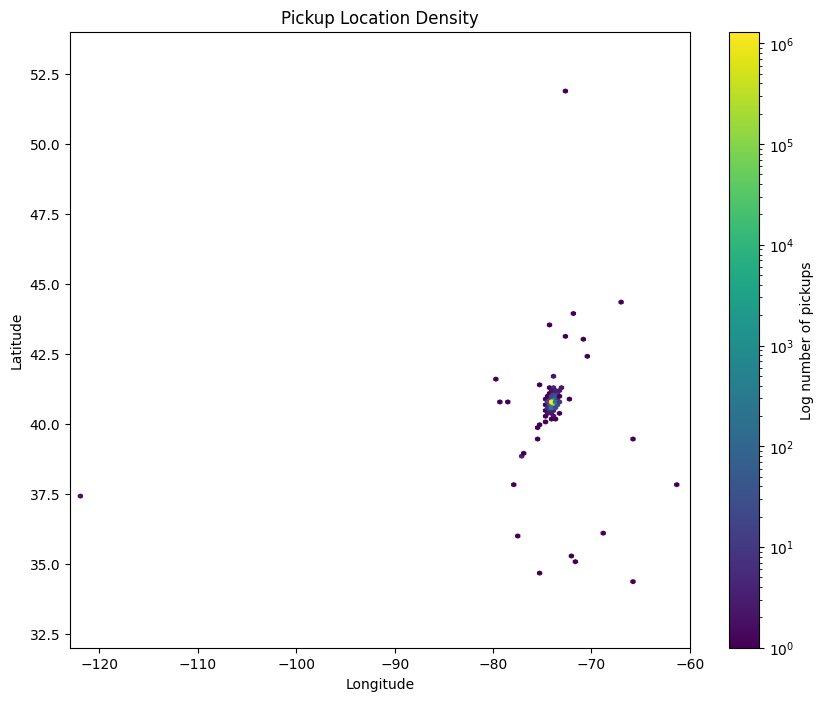

In [37]:
#pick up location map with everything

# Optional: restrict the plot to the main NYC area
nyc_pickups = df_train[
    df_train["pickup_longitude"].between(-123, -60)
    & df_train["pickup_latitude"].between(32, 54)
]

plt.figure(figsize=(10, 8))

plt.hexbin(
    nyc_pickups["pickup_longitude"],
    nyc_pickups["pickup_latitude"],
    gridsize=150,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Log number of pickups")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Pickup Location Density")
plt.xlim(-123, -60)
plt.ylim(32, 54)
plt.show()

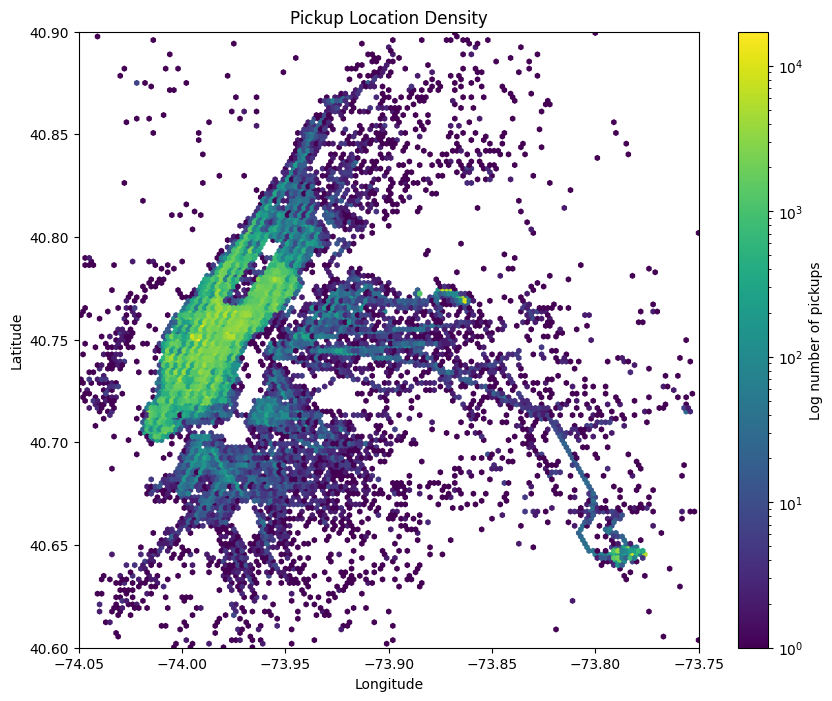

In [38]:
# pick up location map of only main NYC area

# Optional: restrict the plot to the main NYC area
nyc_pickups = df_train[
    df_train["pickup_longitude"].between(-74.05, -73.75)
    & df_train["pickup_latitude"].between(40.60, 40.90)
]

plt.figure(figsize=(10, 8))

plt.hexbin(
    nyc_pickups["pickup_longitude"],
    nyc_pickups["pickup_latitude"],
    gridsize=150,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Log number of pickups")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Pickup Location Density")
plt.xlim(-74.05, -73.75)
plt.ylim(40.60, 40.90)
plt.show()

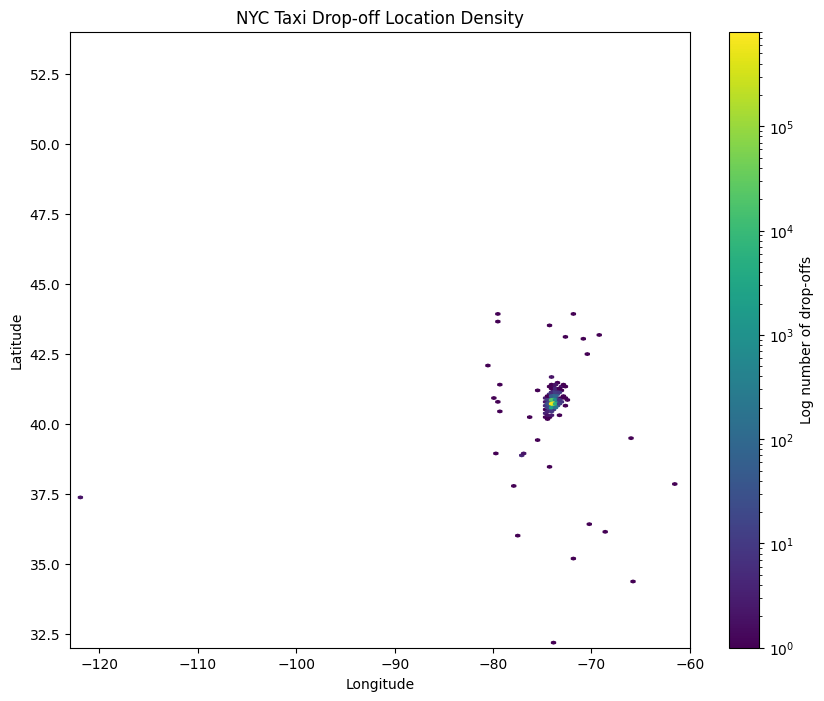

In [39]:
import matplotlib.pyplot as plt

# Keep coordinates within the main NYC area
nyc_dropoffs = df_train[
    df_train["dropoff_longitude"].between(-123, -60)
    & df_train["dropoff_latitude"].between(32, 54)
]

plt.figure(figsize=(10, 8))

dropoff_map = plt.hexbin(
    nyc_dropoffs["dropoff_longitude"],
    nyc_dropoffs["dropoff_latitude"],
    gridsize=150,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(dropoff_map, label="Log number of drop-offs")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("NYC Taxi Drop-off Location Density")

plt.xlim(-123, -60)
plt.ylim(32, 54)

plt.show()

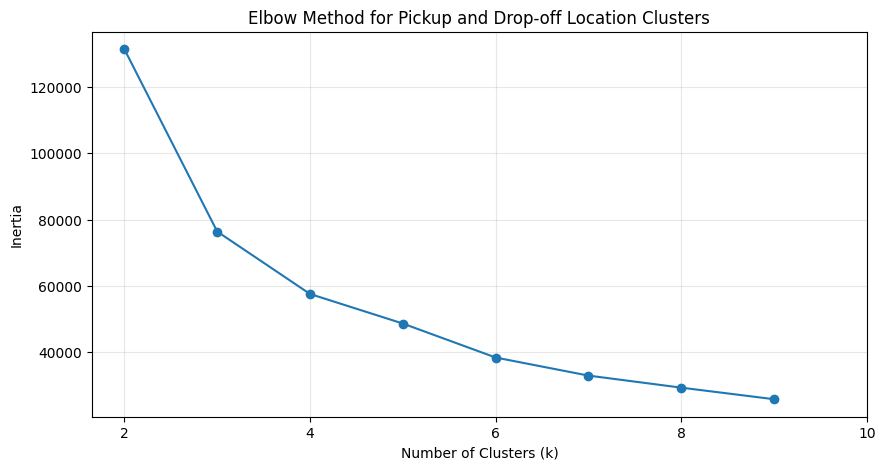

In [41]:

from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler


# Combine pickup and drop-off coordinates
pickup_coordinates = df_train[
    ["pickup_latitude", "pickup_longitude"]
].rename(
    columns={
        "pickup_latitude": "latitude",
        "pickup_longitude": "longitude"
    }
)

dropoff_coordinates = df_train[
    ["dropoff_latitude", "dropoff_longitude"]
].rename(
    columns={
        "dropoff_latitude": "latitude",
        "dropoff_longitude": "longitude"
    }
)

all_coordinates = pd.concat(
    [pickup_coordinates, dropoff_coordinates],
    ignore_index=True
).dropna()


# # Optional but recommended: remove clearly invalid geographic points
# all_coordinates = all_coordinates[
#     all_coordinates["longitude"].between(-74.30, -73.60)
#     & all_coordinates["latitude"].between(40.45, 41.00)
# ]


# Sample coordinates so the elbow calculation runs faster
coordinate_sample = all_coordinates.sample(
    n=min(100_000, len(all_coordinates)),
    random_state=42
)


# Scale latitude and longitude
scaler = StandardScaler()

coordinates_scaled = scaler.fit_transform(
    coordinate_sample[["latitude", "longitude"]]
)


# Calculate inertia for different values of k
k_values = range(2, 10)
inertias = []

for k in k_values:
    kmeans = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=4096,
        n_init=10
    )

    kmeans.fit(coordinates_scaled)
    inertias.append(kmeans.inertia_)


# Plot the elbow graph
plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.xticks(range(2, 11, 2))
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Pickup and Drop-off Location Clusters")
plt.grid(alpha=0.3)

plt.show()

In [42]:
candidate_k = [2, 3, 4, 5, 6, 7]

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in candidate_k:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=4096,
        n_init=10
    )

    labels = model.fit_predict(coordinates_scaled)

    score = silhouette_score(
        coordinates_scaled,
        labels,
        sample_size=min(20_000, len(coordinates_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

for k, score in zip(candidate_k, silhouette_scores):
    print(f"k={k}: silhouette score={score:.4f}")

k=2: silhouette score=0.7829
k=3: silhouette score=0.4297
k=4: silhouette score=0.4031
k=5: silhouette score=0.4293
k=6: silhouette score=0.4128
k=7: silhouette score=0.3929


In [45]:
from sklearn.cluster import MiniBatchKMeans
import pandas as pd

model_2 = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    batch_size=4096,
    n_init=10
)

labels_2 = model_2.fit_predict(coordinates_scaled)

pd.Series(labels_2).value_counts(normalize=True).sort_index()

0    0.42248
1    0.01808
2    0.46457
3    0.06235
4    0.03252
Name: proportion, dtype: float64

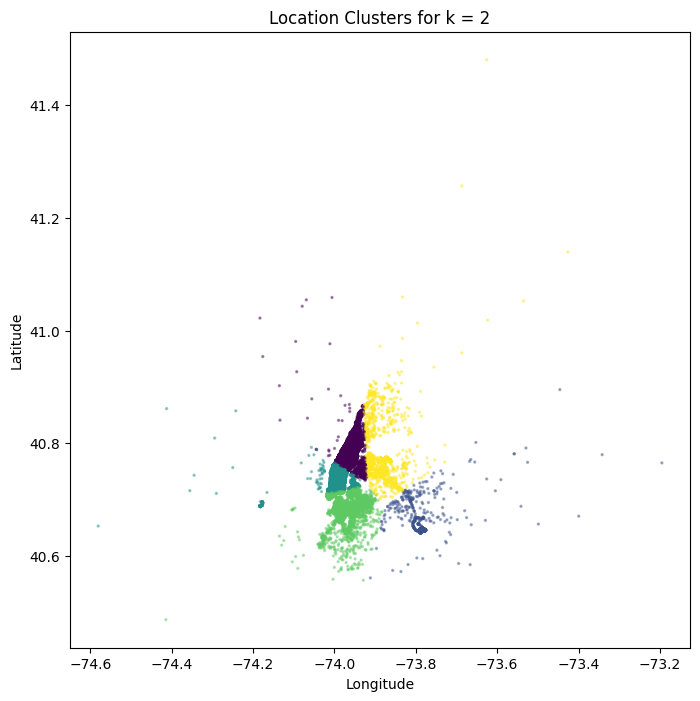

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.scatter(
    coordinate_sample["longitude"],
    coordinate_sample["latitude"],
    c=labels_2,
    s=2,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Location Clusters for k = 2")
plt.show()

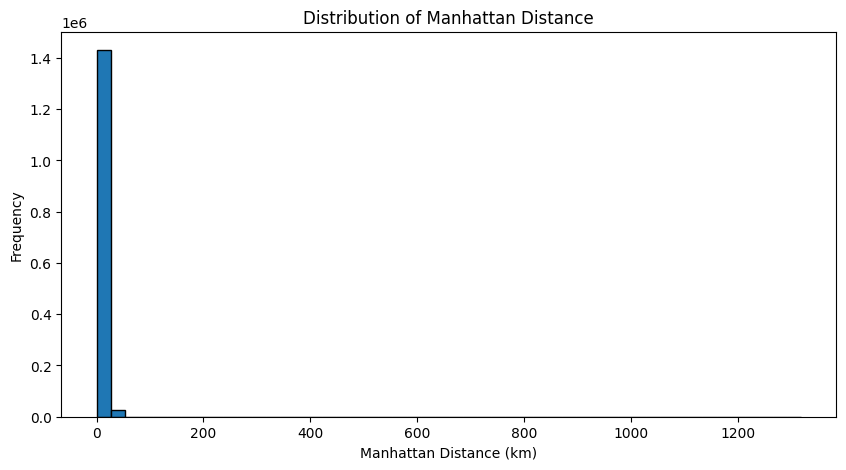

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["manhattan_distance"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Manhattan Distance (km)")
plt.ylabel("Frequency")
plt.title("Distribution of Manhattan Distance")

plt.show()

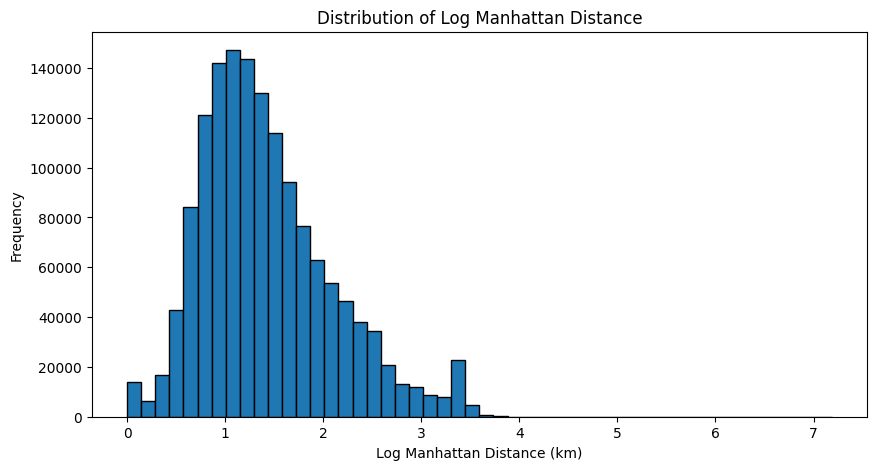

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["log_manhattan_distance"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Log Manhattan Distance (km)")
plt.ylabel("Frequency")
plt.title("Distribution of Log Manhattan Distance")

plt.show()

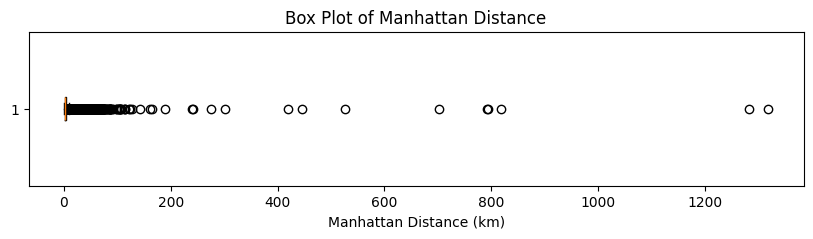

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))

plt.boxplot(
    df_train["manhattan_distance"],
    vert=False
)

plt.xlabel("Manhattan Distance (km)")
plt.title("Box Plot of Manhattan Distance")

plt.show()

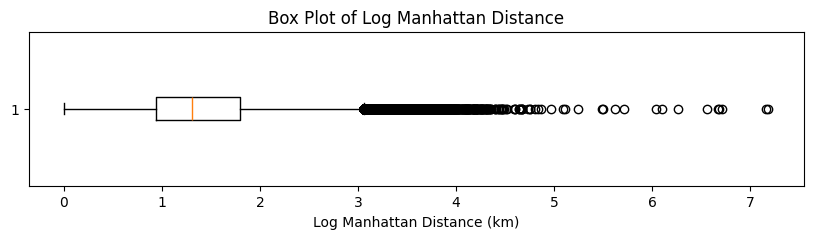

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))

plt.boxplot(
    df_train["log_manhattan_distance"],
    vert=False
)

plt.xlabel("Log Manhattan Distance (km)")
plt.title("Box Plot of Log Manhattan Distance")

plt.show()

In [52]:
# Calculate the quartiles
Q1 = df_train["manhattan_distance"].quantile(0.25)
Q3 = df_train["manhattan_distance"].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
manhattan_outliers = (
    (df_train["manhattan_distance"] < lower_bound) |
    (df_train["manhattan_distance"] > upper_bound)
)

# Calculate the percentage of outliers
manhattan_outlier_percentage = manhattan_outliers.mean() * 100

print(f"Outlier percentage: {manhattan_outlier_percentage:.2f}%")
print(f"Number of outliers: {manhattan_outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

Outlier percentage: 9.27%
Number of outliers: 135,151
Total observations: 1,458,644


In [53]:
var = "log_manhattan_distance"

# Calculate the quartiles
Q1 = df_train[var].quantile(0.25)
Q3 = df_train[var].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = (
    (df_train[var] < lower_bound) |
    (df_train[var] > upper_bound)
)

# Calculate the percentage of outliers
outlier_percentage = outliers.mean() * 100

print(f"{var} outlier percentage: {outlier_percentage:.2f}%")
print(f"Number of outliers: {outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

log_manhattan_distance outlier percentage: 2.88%
Number of outliers: 41,998
Total observations: 1,458,644


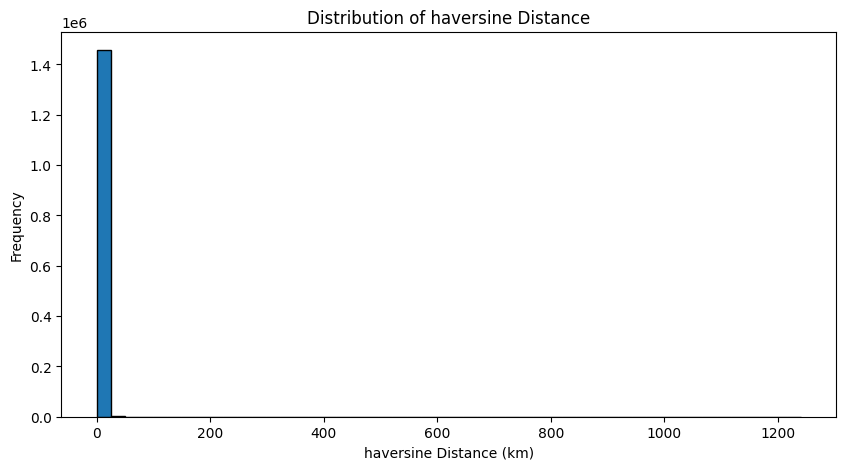

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["haversine_distance"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("haversine Distance (km)")
plt.ylabel("Frequency")
plt.title("Distribution of haversine Distance")

plt.show()

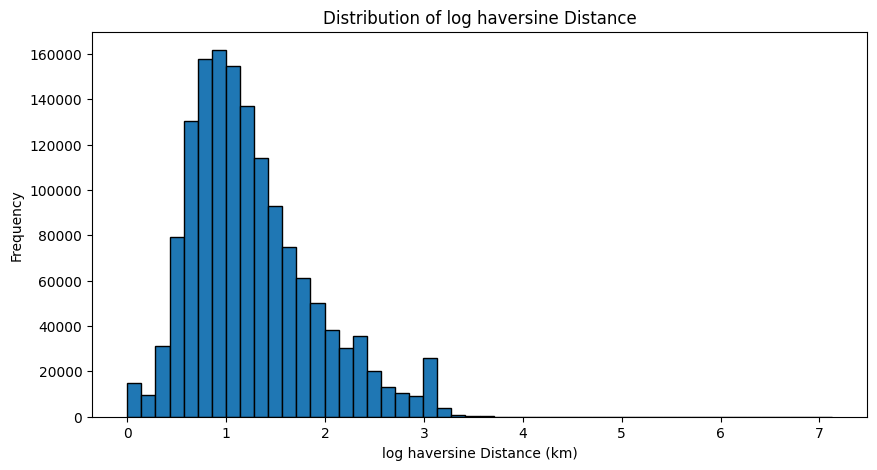

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["log_haversine_distance"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("log haversine Distance (km)")
plt.ylabel("Frequency")
plt.title("Distribution of log haversine Distance")

plt.show()

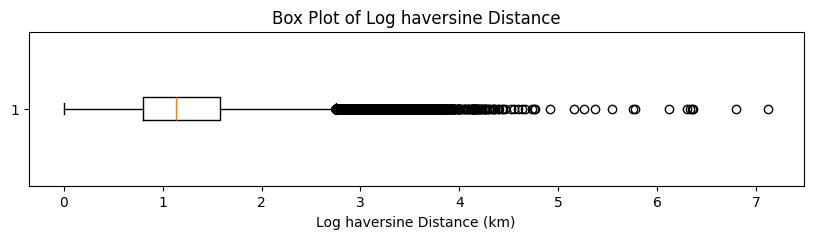

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))

plt.boxplot(
    df_train["log_haversine_distance"],
    vert=False
)

plt.xlabel("Log haversine Distance (km)")
plt.title("Box Plot of Log haversine Distance")

plt.show()

In [57]:
var = "haversine_distance"

# Calculate the quartiles
Q1 = df_train[var].quantile(0.25)
Q3 = df_train[var].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = (
    (df_train[var] < lower_bound) |
    (df_train[var] > upper_bound)
)

# Calculate the percentage of outliers
outlier_percentage = outliers.mean() * 100

print(f"{var} outlier percentage: {outlier_percentage:.2f}%")
print(f"Number of outliers: {outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

haversine_distance outlier percentage: 9.64%
Number of outliers: 140,673
Total observations: 1,458,644


In [58]:
var = "log_haversine_distance"

# Calculate the quartiles
Q1 = df_train[var].quantile(0.25)
Q3 = df_train[var].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = (
    (df_train[var] < lower_bound) |
    (df_train[var] > upper_bound)
)

# Calculate the percentage of outliers
outlier_percentage = outliers.mean() * 100

print(f"{var} outlier percentage: {outlier_percentage:.2f}%")
print(f"Number of outliers: {outliers.sum():,}")
print(f"Total observations: {len(df_train):,}")

log_haversine_distance outlier percentage: 3.19%
Number of outliers: 46,461
Total observations: 1,458,644


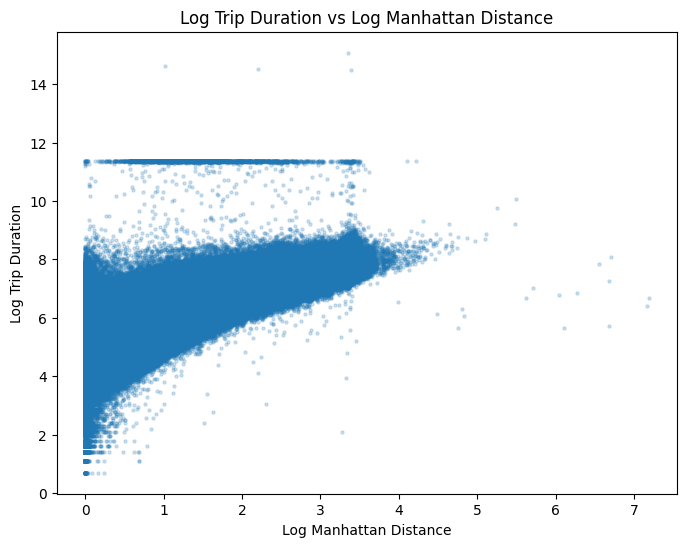

In [59]:
var = "log_manhattan_distance"

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    df_train[var],
    df_train["log_trip_duration"],
    alpha=0.2,
    s=5
)

plt.xlabel(var.replace("_", " ").title())
plt.ylabel("Log Trip Duration")
plt.title(f"Log Trip Duration vs {var.replace('_', ' ').title()}")

plt.show()

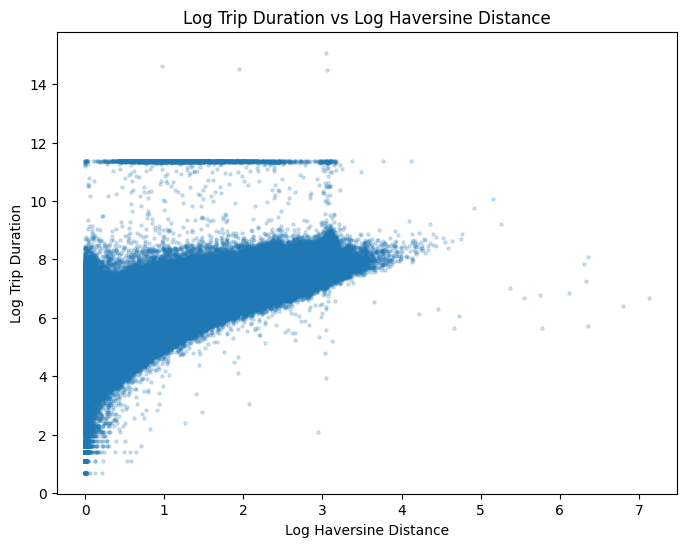

In [60]:
var = "log_haversine_distance"

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    df_train[var],
    df_train["log_trip_duration"],
    alpha=0.2,
    s=5
)

plt.xlabel(var.replace("_", " ").title())
plt.ylabel("Log Trip Duration")
plt.title(f"Log Trip Duration vs {var.replace('_', ' ').title()}")

plt.show()

In [67]:
df_train['trip_duration'].describe()

count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.620000e+02
75%      1.075000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

In [66]:
df_train.nlargest(
    200,
    "trip_duration"
)

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,...,hour_sin_pickup_datetime,hour_cos_pickup_datetime,dow_pickup_datetime,dow_sinpickup_datetime,dow_cospickup_datetime,month_pickup_datetime,month_sinpickup_datetime,month_cospickup_datetime,log_haversine_distance,log_manhattan_distance
978383,id0053347,1,2016-02-13 22:46:52,2016-03-25 18:18:14,1,-73.783905,40.648632,-73.978271,40.750202,N,...,-0.500000,8.660254e-01,5,-0.974928,-0.222521,2,0.866025,5.000000e-01,3.039781,3.356616
924150,id1325766,1,2016-01-05 06:14:15,2016-01-31 01:01:07,1,-73.983788,40.742325,-73.985489,40.727676,N,...,1.000000,6.123234e-17,1,0.781831,0.623490,1,0.500000,8.660254e-01,0.968932,1.019629
680594,id0369307,1,2016-02-13 22:38:00,2016-03-08 15:57:38,2,-73.921677,40.735252,-73.984749,40.759979,N,...,-0.500000,8.660254e-01,5,-0.974928,-0.222521,2,0.866025,5.000000e-01,1.943405,2.204279
355003,id1864733,1,2016-01-05 00:19:42,2016-01-27 11:08:38,1,-73.789650,40.643559,-73.956810,40.773087,N,...,0.000000,1.000000e+00,1,0.781831,0.623490,1,0.500000,8.660254e-01,3.051577,3.384611
1234291,id1942836,2,2016-02-15 23:18:06,2016-02-16 23:17:58,2,-73.794525,40.644825,-73.991051,40.755573,N,...,-0.258819,9.659258e-01,0,0.000000,1.000000,2,0.866025,5.000000e-01,3.074669,3.397711
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54178,id2349061,2,2016-02-27 11:42:44,2016-02-28 11:41:19,1,-73.981049,40.781860,-73.976234,40.794949,N,...,0.258819,-9.659258e-01,5,-0.974928,-0.222521,2,0.866025,5.000000e-01,0.920572,1.051060
217688,id3858198,2,2016-03-06 17:23:16,2016-03-07 17:21:51,4,-73.993629,40.762047,-73.981491,40.780602,N,...,-0.965926,-2.588190e-01,6,-0.781831,0.623490,3,1.000000,6.123234e-17,1.194685,1.407446
752941,id0266147,2,2016-01-03 16:43:22,2016-01-04 16:41:57,1,-74.001892,40.745811,-73.991928,40.725567,N,...,-0.866025,-5.000000e-01,6,-0.781831,0.623490,1,0.500000,8.660254e-01,1.224524,1.408665
888982,id0160780,2,2016-02-16 10:34:50,2016-02-17 10:33:25,1,-73.959290,40.771645,-73.987495,40.764534,N,...,0.500000,-8.660254e-01,1,0.781831,0.623490,2,0.866025,5.000000e-01,1.253756,1.426927


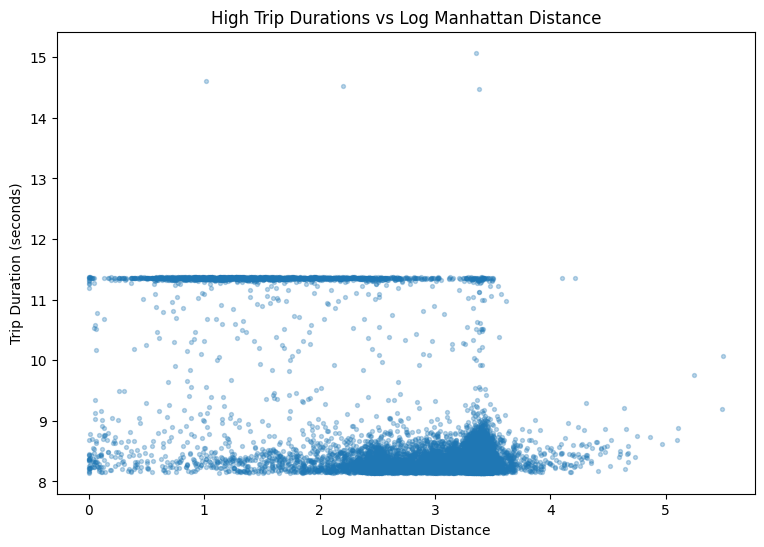

In [69]:
var = "log_manhattan_distance"

high_duration_threshold = df_train["log_trip_duration"].quantile(0.99)

high_duration_data = df_train[
    df_train["log_trip_duration"] >= high_duration_threshold
]

plt.figure(figsize=(9, 6))

plt.scatter(
    high_duration_data[var],
    high_duration_data["log_trip_duration"],
    alpha=0.3,
    s=8
)

plt.xlabel(var.replace("_", " ").title())
plt.ylabel("Trip Duration (seconds)")
plt.title(f"High Trip Durations vs {var.replace('_', ' ').title()}")

plt.show()

In [70]:
df_train[
    df_train["trip_duration"].between(86300, 86400)
]["trip_duration"].describe()

count      251.000000
mean     86332.956175
std         20.805049
min      86301.000000
25%      86316.000000
50%      86331.000000
75%      86346.000000
max      86392.000000
Name: trip_duration, dtype: float64

In [71]:
near_day = df_train["trip_duration"].between(86300, 86400)

df_train.loc[
    near_day,
    ["trip_duration", "manhattan_distance", "haversine_distance"]
].describe()

,trip_duration,manhattan_distance,haversine_distance
count,251.000000,251.000000,251.000000
mean,86332.956175,4.242881,3.301215
std,20.805049,4.522991,3.461216
min,86301.000000,0.000000,0.000000
25%,86316.000000,1.688758,1.334629
50%,86331.000000,2.670011,2.133388
75%,86346.000000,5.121415,4.130474
max,86392.000000,29.137147,21.117104



4. Numeric Feature Analysis
   - passenger_count

5. Categorical Feature Analysis
   - vendor
   - store_and_fwd_flag

6. Relationships with Target
   - scatterplots
   - boxplots
